<a href="https://colab.research.google.com/github/bonobobit/qff2026/blob/main/string_matching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A quantum algorithm for string matching.
Implementazione dell'algoritmo descritto in
Niroula, P., Nam, Y. A quantum algorithm for string matching. npj Quantum Inf 7, 37 (2021). https://doi.org/10.1038/s41534-021-00369-3

In [2]:
%pip install qiskit pylatexenc numpy qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 91.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit_aer]


In [7]:
from qiskit import QuantumRegister, QuantumCircuit
import numpy as np
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator

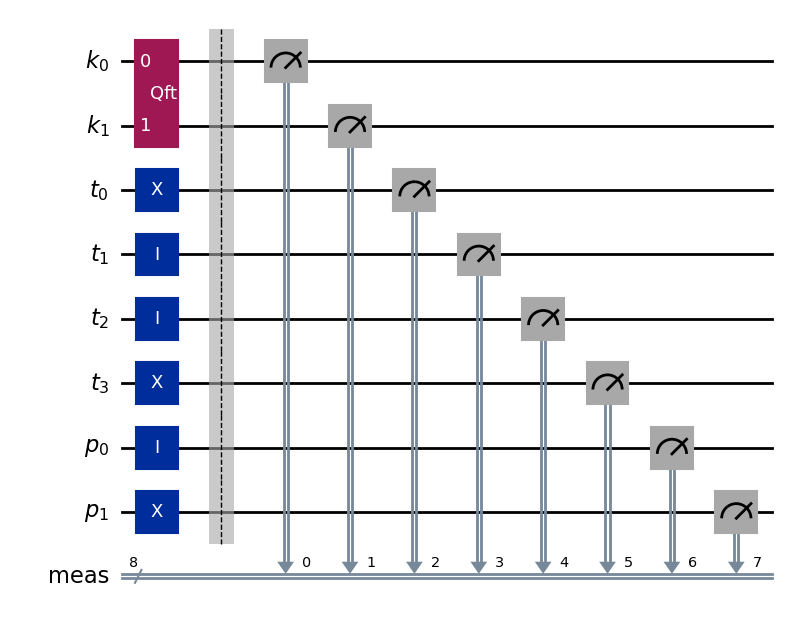

In [19]:
# 1. Inizializzazione dei registri

# Otteniamo stringa e pattern
T = "1001"
P = "01"

# Ricaviamo lunghezza di T e P; n sono i qubit necessari per rappresentare N
N = len(T)
M = len(P)
n = int(np.ceil(np.log2(N)))

# Creiamo i registri
reg_K = QuantumRegister(n, name="k") # registro indice
reg_T = QuantumRegister(N, name="t") # registro stringa
reg_P = QuantumRegister(M, name="p") # registro pattern

qc = QuantumCircuit(reg_K, reg_T, reg_P)

# Popoliamo i registri usando identità e bit-flip come indicato nel paper
for i in range(N):
  if T[i] == "1":
    qc.x(reg_T[i])
  elif T[i] == "0":
    qc.id(reg_T[i])
  else:
    print("Errore nella codifica della stringa T")

for i in range(M):
  if P[i] == "1":
    qc.x(reg_P[i])
  elif P[i] == "0":
    qc.id(reg_P[i])
  else:
    print("Errore nella codifica del pattern")

# 2a. Usiamo la Quantum Fourier Transform per mettere in superposizione i k
qc.append(QFTGate(n), range(n))

# 2b. Implementiamo lo shift ciclico
# L'operatore S agisce sui primi due registri.
# Consideriamo K nella sua codifica binaria,
# per k_j avremo uno shift di 2^j

# Seconda implementazione di S: swap gate controllati
# sono in serie, prossima implementazione: in parallelo

# (!) Per questo algoritmo assumiamo N = 2^p, con p in N,
# non per forza N = 2^n ma comunque una potenza di 2.

for z in range(n):
  k = 2**z
  for i in range(int(np.log2(N)-np.log2(k)), 0, -1): # ordine inverso perché leftward
    for j in range(N//((2**i)*k)):
      for x in range(j*k*(2**i), (j*(2**i)+1)*k):
        qc.cswap(reg_K[z], reg_T[x], reg_T[x+(2**(i-1))*k])




qc.measure_all()
qc.draw('mpl')